# AirLab — ITS · грибы · UNITE v10.0 — полный анализ с исходных FASTQ

FASTQ → FastQC/MultiQC → проверка праймеров → Cutadapt → фильтрация DADA2 → обучение ошибок → денойзинг → объединение → ASV → химеры → таксономия → `phyloseq` → альфа-/бета-разнообразие → предварительные связи с погодой.

- Вход: только **исходные FASTQ**, **референсная FASTA** и опубликованные метаданные (их базовая копия встроена в ноутбук; внешний `metadata/samples_pnas.tsv` используется лишь как обновляемый источник метаданных, если он присутствует).
- Результаты будут записаны в `~/airlab/pipeline/results/ITS/`. Исходные FASTQ не изменяются.
- Запускай ячейки **сверху вниз** (`Shift+Enter`), в R-ядре окружения `~/airlab/envs/amplicon` на выделенном через SLURM вычислительном узле. На `sms` расчёты не запускать.

**ITS:** ампликоны имеют неодинаковую длину; НЕ задаём фиксированный `truncLen`. Таксономия выполняется по **UNITE General FASTA** (all eukaryotes); `addSpecies()` не запускается. Сохраняются *все* ITS ASV и отдельная таблица уверенно классифицированных **Fungi**; по умолчанию экологический анализ использует Fungi. Неидентифицированные как Fungi ASV не объявляются «не-грибами» — их исходная классификация сохраняется.

**Статус исследования:** без отрицательных контролей нельзя считать выполненной проверку загрязнений (`decontam`), а без реальных измерений погоды — анализ экстремальных явлений. Статистика по Flight/Ground предварительная, не причинная. Это адаптированный анализ, не идентичное воспроизведение опубликованной версии QIIME2/референсов.

Официальные инструкции: [DADA2](https://benjjneb.github.io/dada2/tutorial.html), [DADA2 ITS](https://benjjneb.github.io/dada2/ITS_workflow.html), [референсы](https://benjjneb.github.io/dada2/training.html), [Cutadapt](https://cutadapt.readthedocs.io/en/stable/guide.html).

## 0. Установленные зависимости и запуск на кластере

**Используем существующее окружение:** `/home/panishevasa/airlab/envs/amplicon` (R 4.5.3, DADA2, phyloseq, ShortRead, Biostrings, vegan, ggplot2, IRkernel, FastQC, MultiQC, Cutadapt). В ноутбуке есть явная проверка наличия пакетов и программ.

Если окружение когда-нибудь придётся **создать заново**, это делается **на `sms`** (вычислительные узлы могут не иметь доступа в интернет), а не внутри R:

```bash
~/tools/bin/micromamba create -y -p ~/airlab/envs/amplicon -c conda-forge -c bioconda \
  r-base=4.5 bioconductor-dada2 bioconductor-phyloseq \
  bioconductor-shortread bioconductor-biostrings r-vegan r-ggplot2 \
  fastqc multiqc cutadapt jupyterlab r-irkernel
```

JupyterLab запускается после `srun -p normal -c 2 -t 03:00:00 --pty bash`, на назначенном узле. Для Windows нужен SSH-туннель вида `ssh -N -L 8888:cn-XXX:8888 panishevasa@АДРЕС_СЕРВЕРА`. `cn-XXX` — реально выделенный узел.

**Ресурсы:** для DADA2 может потребоваться более длительное SLURM-задание. Сохранённый `.rds` не заменяет повторного выполнения ячеек, но позволяет анализировать результаты в отдельной будущей сессии.

## 1. Настройки и функции

Все параметры заданы **в этом ноутбуке**: внешний `config.yaml` **не требуется**. Если меняешь параметры, перезапусти анализ **с первой ячейки** и не смешивай результаты двух настроек. Параллельность ограничена количеством ядер, выделенных SLURM.

In [2]:
project_dir <- "/home/panishevasa/airlab/pipeline"
raw_dir <- "/home/panishevasa/airlab/test_16S_ITS_data"
env_bin <- "/home/panishevasa/airlab/envs/amplicon/bin"
marker <- "ITS"
primer_fwd <- "TAGAGGAAGTAAAAGTCGTAA"
primer_rev <- "TTYRCTRCGTTCTTCATC"
taxonomy_ref <- file.path(project_dir, "refdb/unite_v10.0/sh_general_release_dynamic_s_all_19.02.2025.fasta")
species_ref <- NULL
tax_levels <- c("Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species")
try_rc <- TRUE
fungi_only <- TRUE  # Анализ гриба: оставляем уверенно классифицированные Fungi

run_fastqc <- TRUE
max_ee <- c(2, 2)
trunc_len <- c(0L, 0L)
min_len <- 50L
min_reads <- 100L
min_boot <- 80L
pooling <- "pseudo"
min_overlap <- 12L
min_pilot_retention <- 0.50  # защита от ошибочных праймеров
set.seed(139)

if (!dir.exists(project_dir)) stop("Missing project directory: ", project_dir)
if (!dir.exists(raw_dir)) stop("Missing raw FASTQ directory: ", raw_dir)
if (grepl("^sms", Sys.info()[["nodename"]])) stop("Compute on a SLURM compute node, not sms")

Sys.setenv(PATH=paste(env_bin, Sys.getenv("PATH"), sep=":"))
needed <- c("dada2", "ShortRead", "Biostrings", "phyloseq", "vegan", "ggplot2")
missing <- needed[!vapply(needed, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing)) stop("Missing R packages: ", paste(missing, collapse=", "))
cli <- c("cutadapt", if (run_fastqc) c("fastqc", "multiqc"))
if (any(!nzchar(Sys.which(cli)))) stop("Missing commands: ", paste(cli[!nzchar(Sys.which(cli))], collapse=", "))
if (!file.exists(taxonomy_ref)) stop("Missing reference FASTA: ", taxonomy_ref)
if (!is.null(species_ref) && !file.exists(species_ref)) stop("Missing SILVA species FASTA: ", species_ref)

allocated <- suppressWarnings(as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1")))
if (!is.finite(allocated) || allocated < 1L) allocated <- 1L
threads <- min(4L, allocated)
outdir <- file.path(project_dir, "results", marker)
dir.create(outdir, recursive=TRUE, showWarnings=FALSE)

run_cmd <- function(exe, arguments, log_file) {
  dir.create(dirname(log_file), recursive=TRUE, showWarnings=FALSE)
  rc <- suppressWarnings(system2(Sys.which(exe), args=shQuote(as.character(arguments)),
                                 stdout=log_file, stderr=log_file))
  if (!identical(as.integer(rc), 0L)) {
    if (file.exists(log_file)) cat(tail(readLines(log_file, warn=FALSE), 25), sep="\n")
    stop(exe, " returned exit status ", rc, "; log: ", log_file)
  }
  invisible(rc)
}
write_matrix <- function(x, filename) {
  write.table(x, file.path(outdir, filename), sep="\t", quote=FALSE,
              col.names=NA, na="NA")
}
write_rows <- function(x, filename) {
  write.table(x, file.path(outdir, filename), sep="\t", quote=FALSE,
              row.names=FALSE, na="NA")
}
get_cutadapt_n <- function(log_lines, phrase) {
  hit <- grep(phrase, log_lines, value=TRUE, fixed=TRUE)
  if (!length(hit)) return(NA_real_)
  as.numeric(gsub(",", "", sub(".*:[[:space:]]*([0-9,]+).*", "\\1", hit[1])))
}

cat("Marker:", marker, "| threads:", threads,
    "| results:", outdir, "\nReference:", taxonomy_ref, "\n")

Marker: ITS | threads: 2 | results: /home/panishevasa/airlab/pipeline/results/ITS 
Reference: /home/panishevasa/airlab/pipeline/refdb/unite_v10.0/sh_general_release_dynamic_s_all_19.02.2025.fasta 


## 2. Поиск исходных FASTQ и метаданные PNAS

Строгая проверка имён пар R1/R2: нельзя объединять несовпадающие образцы. Если файла нет/он пуст, прекращаем запуск. Базовые метаданные PNAS 2024 (Supplementary Table 1) **встроены** в этот ноутбук; если существует `metadata/samples_pnas.tsv`, используем его вместо встроенной таблицы. Это входные метаданные, а не рассчитанные результаты.

In [3]:
all_files <- list.files(raw_dir, full.names=TRUE)
suffix_f <- paste0("_1_", marker, ".fastq.gz")
suffix_r <- paste0("_2_", marker, ".fastq.gz")
fn_f <- all_files[endsWith(basename(all_files), suffix_f)]
fn_r <- all_files[endsWith(basename(all_files), suffix_r)]
ids_f <- substr(basename(fn_f), 1L, nchar(basename(fn_f)) - nchar(suffix_f))
ids_r <- substr(basename(fn_r), 1L, nchar(basename(fn_r)) - nchar(suffix_r))
if (!length(ids_f) || anyDuplicated(ids_f) || anyDuplicated(ids_r) || !setequal(ids_f, ids_r)) {
  cat("Missing R2 for:", paste(setdiff(ids_f, ids_r), collapse=", "), "\n")
  cat("Missing R1 for:", paste(setdiff(ids_r, ids_f), collapse=", "), "\n")
  stop("Incomplete or duplicated R1/R2 pairs")
}
order_f <- order(ids_f)
fn_f <- fn_f[order_f]; sample_ids <- ids_f[order_f]
fn_r <- fn_r[match(sample_ids, ids_r)]
names(fn_f) <- names(fn_r) <- sample_ids
if (!all(file.info(c(fn_f, fn_r))$size > 0)) stop("Empty FASTQ files detected")
cat("Complete FASTQ pairs:", length(sample_ids), "\n")

metadata_embedded <- "sample_id\tis_control\tsite_id\tsite_type\tsampling_date\tdatetime_start\tdatetime_end\tsampling_timezone\taltitude_min_m\taltitude_max_m\tair_volume_m3\tdna_yield_ng_m3\tpublished_16S_success\tpublished_ITS_success\textraction_batch\tlibrary_batch\tseason\ttemp_c\trh_pct\twind_ms\tprecip_mm\tpressure_hpa\tpm25\tpm10\tmetadata_source\nS1\tFALSE\tNA\tFlight\t2014-02-22\t2014-02-22T12:10:00\t2014-02-22T15:00:00\tAsia/Tokyo\t1000\t3000\t83.6\t0.155\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS2\tFALSE\tNA\tGround\t2014-02-23\t2014-02-23T00:00:00\t2014-02-23T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.134\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS3\tFALSE\tNA\tFlight\t2014-02-23\t2014-02-23T12:04:00\t2014-02-23T14:50:00\tAsia/Tokyo\t1000\t3000\t83.7\t0.140\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS4\tFALSE\tNA\tGround\t2014-02-24\t2014-02-24T00:00:00\t2014-02-24T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.078\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS5\tFALSE\tNA\tFlight\t2014-02-24\t2014-02-24T12:04:00\t2014-02-24T14:38:00\tAsia/Tokyo\t1000\t3000\t84.0\t0.240\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS6\tFALSE\tNA\tGround\t2014-02-25\t2014-02-25T00:00:00\t2014-02-25T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.354\tYES\tNO\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS7\tFALSE\tNA\tFlight\t2014-02-25\t2014-02-25T12:18:00\t2014-02-25T15:00:00\tAsia/Tokyo\t1000\t3000\t88.4\t0.041\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS8\tFALSE\tNA\tGround\t2014-02-26\t2014-02-26T00:00:00\t2014-02-26T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.087\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS9\tFALSE\tNA\tFlight\t2014-02-26\t2014-02-26T12:24:00\t2014-02-26T15:10:00\tAsia/Tokyo\t1000\t3000\t82.6\t0.051\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS10\tFALSE\tNA\tGround\t2014-02-27\t2014-02-27T00:00:00\t2014-02-27T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.089\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS11\tFALSE\tNA\tGround\t2014-02-28\t2014-02-28T12:00:00\t2014-02-28T15:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.095\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS12\tFALSE\tNA\tGround\t2014-03-01\t2014-03-01T00:00:00\t2014-03-01T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.162\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS13\tFALSE\tNA\tFlight\t2014-04-01\t2014-04-01T12:10:00\t2014-04-01T14:58:00\tAsia/Tokyo\t1000\t3000\t81.3\t0.053\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS14\tFALSE\tNA\tGround\t2014-04-01\t2014-04-01T00:00:00\t2014-04-01T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.000\tNO\tNO\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS15\tFALSE\tNA\tFlight\t2014-04-05\t2014-04-05T11:50:00\t2014-04-05T14:35:00\tAsia/Tokyo\t1000\t3000\t83.9\t0.035\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS16\tFALSE\tNA\tGround\t2014-04-06\t2014-04-06T00:00:00\t2014-04-06T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.066\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS17\tFALSE\tNA\tFlight\t2014-04-06\t2014-04-06T10:47:00\t2014-04-06T13:11:00\tAsia/Tokyo\t1000\t3000\t72.9\t0.072\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS18\tFALSE\tNA\tGround\t2014-04-07\t2014-04-07T00:00:00\t2014-04-07T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.004\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS19\tFALSE\tNA\tFlight\t2014-04-07\t2014-04-07T12:15:00\t2014-04-07T14:55:00\tAsia/Tokyo\t1000\t3000\t79.7\t0.047\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS20\tFALSE\tNA\tGround\t2014-04-08\t2014-04-08T00:00:00\t2014-04-08T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.031\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS21\tFALSE\tNA\tFlight\t2014-04-08\t2014-04-08T12:15:00\t2014-04-08T14:53:00\tAsia/Tokyo\t1000\t3000\t79.0\t0.063\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS22\tFALSE\tNA\tGround\t2014-04-09\t2014-04-09T00:00:00\t2014-04-09T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.019\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1"
metadata_path <- file.path(project_dir, "metadata", "samples_pnas.tsv")
if (file.exists(metadata_path)) {
  published <- read.delim(metadata_path, sep="\t", na.strings="NA",
                          stringsAsFactors=FALSE, check.names=FALSE,
                          fileEncoding="UTF-8")
  cat("Metadata source:", metadata_path, "\n")
} else {
  published <- read.delim(text=metadata_embedded, sep="\t", na.strings="NA",
                          stringsAsFactors=FALSE, check.names=FALSE)
  cat("Metadata source: embedded PNAS supplementary table\n")
}
if (!"sample_id" %in% names(published) || anyDuplicated(published$sample_id))
  stop("Invalid sample_id in metadata")
if (!all(sample_ids %in% published$sample_id))
  stop("Metadata missing FASTQ IDs: ", paste(setdiff(sample_ids, published$sample_id), collapse=", "))
meta <- published[match(sample_ids, published$sample_id), , drop=FALSE]
rownames(meta) <- sample_ids
stopifnot(identical(meta$sample_id, sample_ids))
write_rows(meta, "sample_metadata_matched.tsv")

con <- if (grepl("\\.gz$", taxonomy_ref)) gzfile(taxonomy_ref, "rt") else file(taxonomy_ref, "rt")
ref_header <- readLines(con, n=1L, warn=FALSE); close(con)
if (!length(ref_header) || !startsWith(ref_header, ">")) stop("Reference file does not start with a FASTA header")
cat("Reference header:", substr(ref_header, 1, 180), "\n")
cat("Published records:", nrow(published), "| matched:", nrow(meta), "\n")
print(meta[, intersect(c("sample_id", "site_type", "sampling_date", "air_volume_m3",
                        "published_16S_success", "published_ITS_success"), names(meta)), drop=FALSE])

Complete FASTQ pairs: 20 
Metadata source: /home/panishevasa/airlab/pipeline/metadata/samples_pnas.tsv 
Reference header: >Ciliophora_sp|UDB02393310|SH0000001.10FU|reps_singleton|k__Alveolata;p__Ciliophora;c__Ciliophora_cls_Incertae_sedis;o__Ciliophora_ord_Incertae_sedis;f__Ciliophora_fam_Incertae_sed 
Published records: 22 | matched: 20 
    sample_id site_type sampling_date air_volume_m3 published_16S_success
S1         S1    Flight    2014-02-22          83.6                   YES
S10       S10    Ground    2014-02-27          90.0                   YES
S11       S11    Ground    2014-02-28          90.0                   YES
S12       S12    Ground    2014-03-01          90.0                   YES
S13       S13    Flight    2014-04-01          81.3                   YES
S15       S15    Flight    2014-04-05          83.9                   YES
S16       S16    Ground    2014-04-06          90.0                   YES
S17       S17    Flight    2014-04-06          72.9                

## 3. Исходный контроль качества: FastQC + MultiQC

Обрабатываются **все исходные файлы** этого маркера, в том числе повторно при новом запуске. Ошибка FastQC о неполном FASTQ требует восстановления оригинального архива. Графики для первых двух образцов служат предварительной визуальной проверкой.

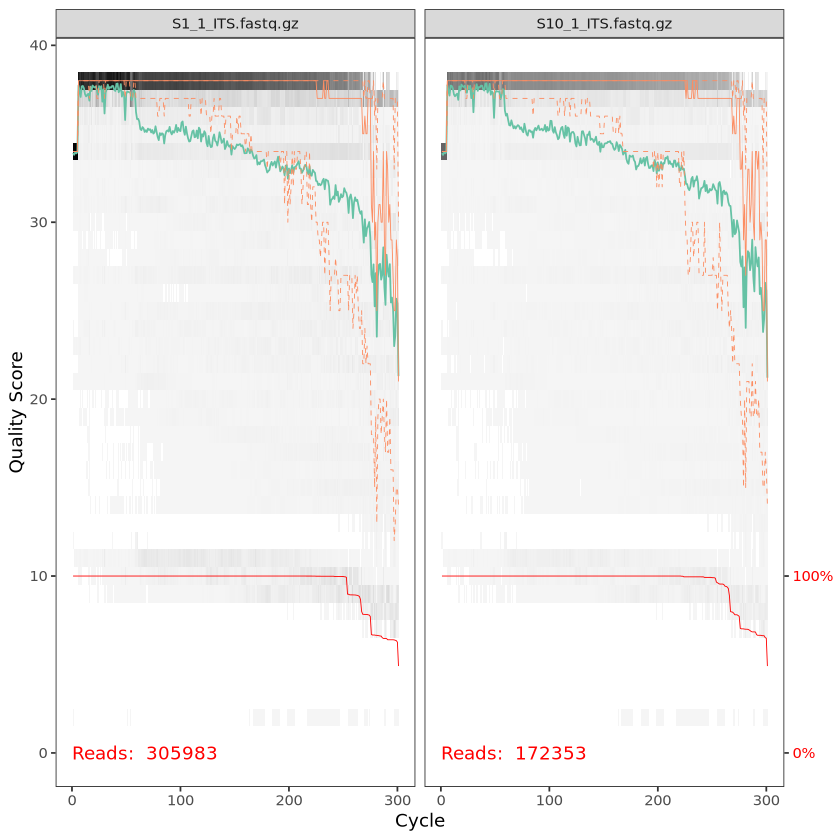

MultiQC: /home/panishevasa/airlab/pipeline/results/ITS/multiqc/multiqc_report.html 


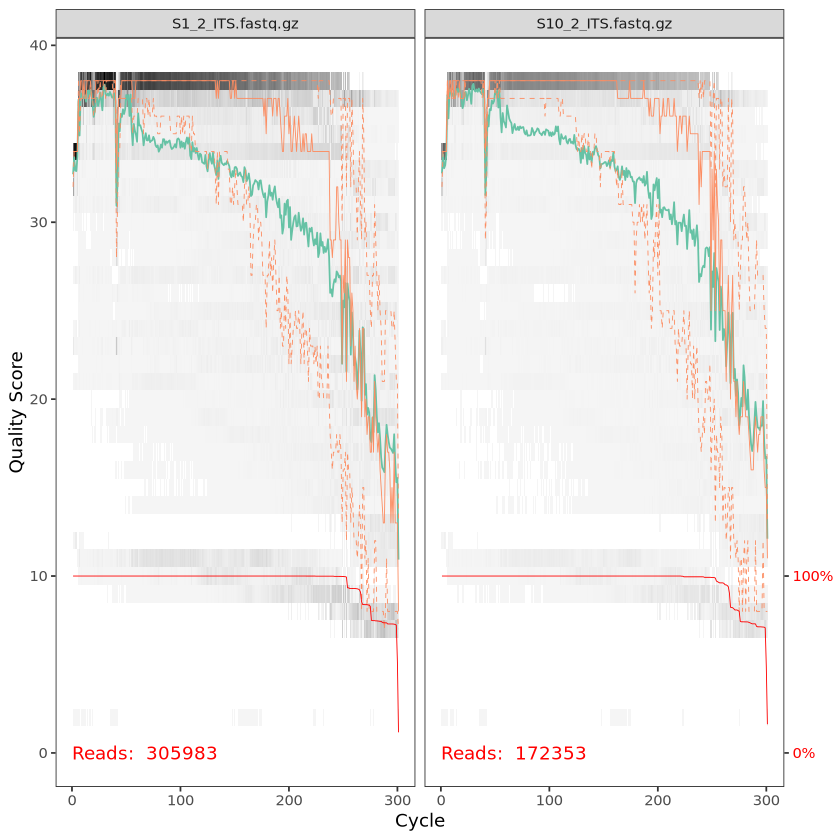

In [4]:
preview_ids <- head(sample_ids, 2L)
print(dada2::plotQualityProfile(unname(fn_f[preview_ids])))
print(dada2::plotQualityProfile(unname(fn_r[preview_ids])))
if (run_fastqc) {
  qcdir <- file.path(outdir, "fastqc")
  mqdir <- file.path(outdir, "multiqc")
  dir.create(qcdir, recursive=TRUE, showWarnings=FALSE)
  dir.create(mqdir, recursive=TRUE, showWarnings=FALSE)
  run_cmd("fastqc", c("-t", threads, "--outdir", qcdir, unname(fn_f), unname(fn_r)),
          file.path(outdir, "fastqc.log"))
  run_cmd("multiqc", c("--force", "--outdir", mqdir, qcdir),
          file.path(outdir, "multiqc.log"))
  cat("MultiQC:", file.path(mqdir, "multiqc_report.html"), "\n")
}

## 4. Ориентация праймеров (первая 500 прочтений на файл)

Проверяем строгие совпадения праймеров с началом R1/R2 с учётом IUPAC. Превышение `swapped_hits` — повод исправить источники R1/R2 вручную, а не автоматически переставлять файлы. Для ITS возможны несовпадения из-за праймерной вариабельности.

In [5]:
primer_hits <- function(path, primer, n=500L) {
  stream <- ShortRead::FastqStreamer(path, n=n)
  on.exit(close(stream))
  fq <- ShortRead::yield(stream)
  if (!length(fq)) return(0L)
  s <- ShortRead::sread(fq)
  s <- s[Biostrings::width(s) >= nchar(primer)]
  if (!length(s)) return(0L)
  st <- Biostrings::subseq(s, start=1L, width=nchar(primer))
  sum(Biostrings::vcountPattern(primer, st, fixed=FALSE) > 0)
}
orientation <- data.frame(sample_id=sample_ids,
  expected_hits=vapply(seq_along(sample_ids), function(i)
    primer_hits(fn_f[i], primer_fwd) + primer_hits(fn_r[i], primer_rev), numeric(1)),
  swapped_hits=vapply(seq_along(sample_ids), function(i)
    primer_hits(fn_f[i], primer_rev) + primer_hits(fn_r[i], primer_fwd), numeric(1)))
write_rows(orientation, "primer_orientation.tsv")
print(orientation, row.names=FALSE)
if (any(orientation$swapped_hits >= 10 & orientation$swapped_hits > orientation$expected_hits))
  stop("Possible R1/R2 swap: inspect primer_orientation.tsv before Cutadapt")

 sample_id expected_hits swapped_hits
        S1           957            0
       S10           971            0
       S11           963            0
       S12           957            0
       S13           955            0
       S15           970            0
       S16           981            0
       S17           961            0
       S18           964            0
       S19           959            0
        S2           978            0
       S20           966            0
       S21           977            0
       S22           960            0
        S3           966            0
        S4           959            0
        S5           964            0
        S7           959            0
        S8           956            0
        S9           965            0


## 5. Cutadapt: удаление праймеров для всех образцов

Используются **связанные адаптеры** (`-a ^5′-праймер...реверс-комплемент 3′-праймера` для R1 и `-A` для R2) в парном режиме. Обязателен 5′-праймер, а возможное 3′-продолжение удаляется для коротких ампликонов. `--pair-filter=any --discard-untrimmed` удаляет всю пару, если один из двух обязательных праймеров не найден. В первой пробе проверяется процент сохранённых пар, затем анализируются все остальные образцы. Входные FASTQ не переписываются.

Важна именно комбинация **`-a`/`-A`**: в Cutadapt 5.2 связанные адаптеры с `-g`/`-G` требовали бы одновременно 5′ и 3′ части, что отбрасывало бы многие длинные ампликоны. Это также устраняет проблему исходного варианта с раздельными адаптерами: теперь случайное совпадение только с 3′-частью не считается успешным удалением праймера.

In [6]:
trimdir <- file.path(outdir, "trimmed")
logdir <- file.path(outdir, "logs")
dir.create(trimdir, recursive=TRUE, showWarnings=FALSE)
dir.create(logdir, recursive=TRUE, showWarnings=FALSE)
trim_f <- setNames(file.path(trimdir, paste0(sample_ids, "_R1.fastq.gz")), sample_ids)
trim_r <- setNames(file.path(trimdir, paste0(sample_ids, "_R2.fastq.gz")), sample_ids)
rc_primer <- function(s) as.character(Biostrings::reverseComplement(Biostrings::DNAString(s)))
linked_f <- paste0("^", primer_fwd, "...", rc_primer(primer_rev))
linked_r <- paste0("^", primer_rev, "...", rc_primer(primer_fwd))
cut_args <- function(i) c("-a", linked_f, "-A", linked_r,
                           "--discard-untrimmed", "--pair-filter=any",
                           "--minimum-length", min_len, "-j", threads,
                           "-o", trim_f[i], "-p", trim_r[i], fn_f[i], fn_r[i])
cut_log <- function(id) file.path(logdir, paste0(id, ".cutadapt.log"))

cat("Pilot Cutadapt sample:", sample_ids[1], "\n")
run_cmd("cutadapt", cut_args(1), cut_log(sample_ids[1]))
pilot_text <- readLines(cut_log(sample_ids[1]), warn=FALSE)
cat(grep("Total read pairs processed|Read 1 with adapter|Read 2 with adapter|Pairs written|Pairs discarded",
         pilot_text, value=TRUE), sep="\n")
pilot_in <- get_cutadapt_n(pilot_text, "Total read pairs processed:")
pilot_out <- get_cutadapt_n(pilot_text, "Pairs written (passing filters):")
if (!is.finite(pilot_in) || !is.finite(pilot_out) || pilot_in == 0 ||
    pilot_out / pilot_in < min_pilot_retention)
  stop("Cutadapt pilot retained too few reads: inspect primers and pilot log")
cat("Pilot retained:", round(100*pilot_out/pilot_in, 2), "%\n")

for (i in seq_along(sample_ids)[-1L]) {
  cat("Cutadapt:", i, "/", length(sample_ids), sample_ids[i], "\n")
  run_cmd("cutadapt", cut_args(i), cut_log(sample_ids[i]))
}
cut_qc <- do.call(rbind, lapply(sample_ids, function(id) {
  x <- readLines(cut_log(id), warn=FALSE)
  before <- get_cutadapt_n(x, "Total read pairs processed:")
  after <- get_cutadapt_n(x, "Pairs written (passing filters):")
  data.frame(sample_id=id, raw_pairs=before, trimmed_pairs=after,
             retained_pct=round(100*after/before, 2))
}))
if (any(!is.finite(cut_qc$retained_pct))) stop("Some Cutadapt summary logs are incomplete")
write_rows(cut_qc, "cutadapt_retention.tsv")
print(cut_qc, row.names=FALSE)
cat("Median Cutadapt retention:", median(cut_qc$retained_pct), "%\n")

Pilot Cutadapt sample: S1 
Total read pairs processed:            305,983
  Read 1 with adapter:                 305,546 (99.9%)
  Read 2 with adapter:                 303,064 (99.0%)
Pairs discarded as untrimmed:            3,317 (1.1%)
Pairs written (passing filters):       302,666 (98.9%)
Pilot retained: 98.92 %
Cutadapt: 2 / 20 S10 
Cutadapt: 3 / 20 S11 
Cutadapt: 4 / 20 S12 
Cutadapt: 5 / 20 S13 
Cutadapt: 6 / 20 S15 
Cutadapt: 7 / 20 S16 
Cutadapt: 8 / 20 S17 
Cutadapt: 9 / 20 S18 
Cutadapt: 10 / 20 S19 
Cutadapt: 11 / 20 S2 
Cutadapt: 12 / 20 S20 
Cutadapt: 13 / 20 S21 
Cutadapt: 14 / 20 S22 
Cutadapt: 15 / 20 S3 
Cutadapt: 16 / 20 S4 
Cutadapt: 17 / 20 S5 
Cutadapt: 18 / 20 S7 
Cutadapt: 19 / 20 S8 
Cutadapt: 20 / 20 S9 
 sample_id raw_pairs trimmed_pairs retained_pct
        S1    305983        302666        98.92
       S10    172353        170779        99.09
       S11    123075        121955        99.09
       S12     94185         93319        99.08
       S13     83150 

## 6. Качество после Cutadapt и фильтрация DADA2

Поскольку Cutadapt изменяет длину прочтений (особенно ITS), **не задаём фиксированную длину обрезки** на первом прогоне: `truncLen=c(0,0)`. Дальше применяем ожидаемые ошибки `maxEE=(2,2)`, `maxN=0`, `truncQ=2`, `rm.phix=TRUE`. Входные файлы после Cutadapt и выходные после DADA2 сохраняются отдельно.

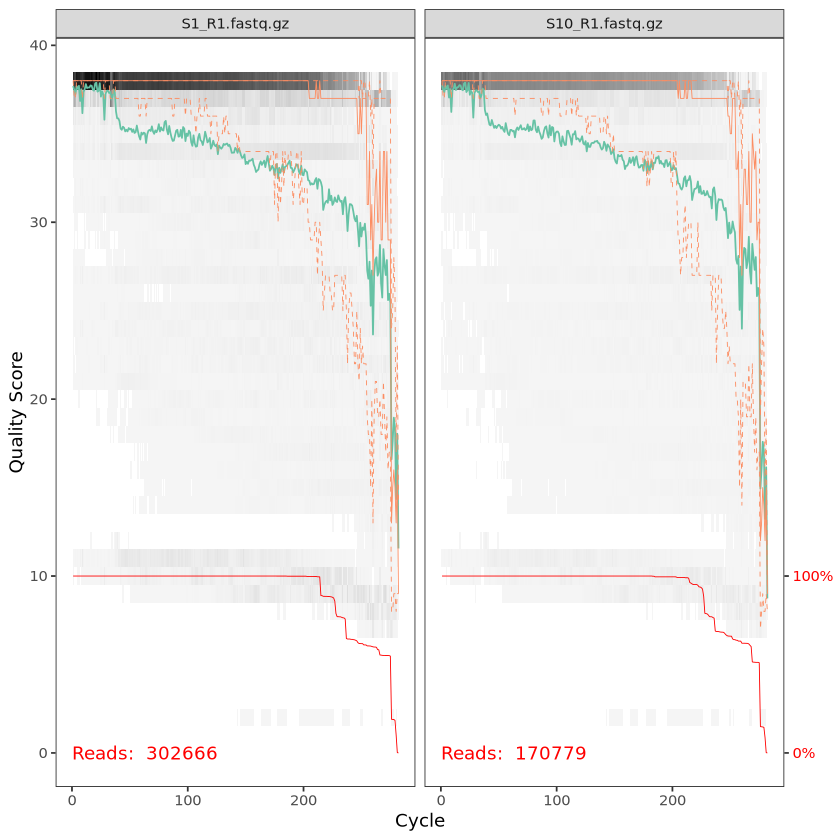

    reads.in reads.out
S1    302666    158183
S10   170779     94668
S11   121955     73865
S12    93319     53346
S13    82275     43543
S15   254594    140478
S16   134778     68096
S17    69721     37583
S18    98699     54595
S19   121338     60916
S2    301291    166190
S20   170876     83095
S21   221791    115922
S22   245738    118014
S3    451772    268566
S4    188248    100098
S5    198542    104404
S7    180579     98903
S8    158566     76015
S9    103593     58539
Retained after quality filtering: 53.8 % | samples: 20 / 20 


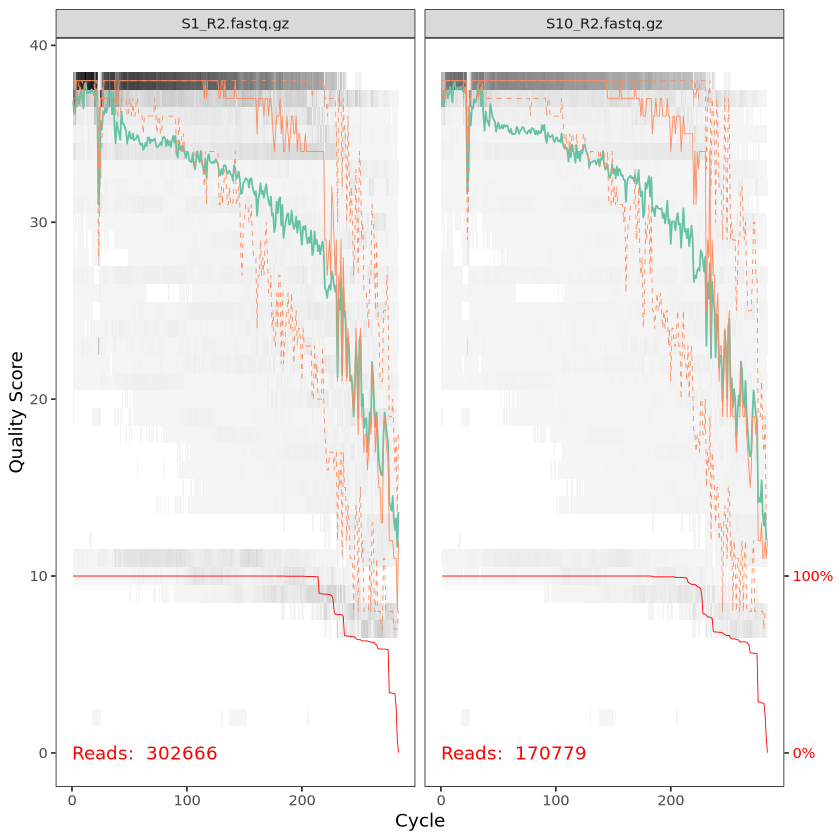

In [7]:
print(dada2::plotQualityProfile(unname(trim_f[preview_ids])))
print(dada2::plotQualityProfile(unname(trim_r[preview_ids])))
filtered_dir <- file.path(outdir, "filtered")
dir.create(filtered_dir, recursive=TRUE, showWarnings=FALSE)
filt_f <- setNames(file.path(filtered_dir, paste0(sample_ids, "_R1.fastq.gz")), sample_ids)
filt_r <- setNames(file.path(filtered_dir, paste0(sample_ids, "_R2.fastq.gz")), sample_ids)
filter_stats <- dada2::filterAndTrim(unname(trim_f), unname(filt_f),
  unname(trim_r), unname(filt_r), truncLen=trunc_len,
  maxN=0, maxEE=max_ee, truncQ=2, minLen=min_len, rm.phix=TRUE,
  compress=TRUE, multithread=threads, verbose=TRUE)
rownames(filter_stats) <- sample_ids
keep <- filter_stats[, "reads.out"] >= min_reads
kept_ids <- sample_ids[keep]
if (!length(kept_ids)) stop("No samples passed DADA2 filter")
saveRDS(filter_stats, file.path(outdir, "filter_stats.rds"))
write_matrix(filter_stats, "filter_stats.tsv")
print(filter_stats)
cat("Retained after quality filtering:",
    round(100 * sum(filter_stats[,"reads.out"]) / sum(filter_stats[,"reads.in"]), 1),
    "% | samples:", length(kept_ids), "/", length(sample_ids), "\n")

## 7. Обучение моделей ошибок DADA2 для R1 и R2

Предупреждения ggplot `scale_y_log10()` при `plotErrors()` возможны из-за нулевых частот; это не означает сбой `learnErrors()`.

106486786 total bases in 423605 reads from 5 samples will be used for learning the error rates.
106627890 total bases in 423605 reads from 5 samples will be used for learning the error rates.


Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”


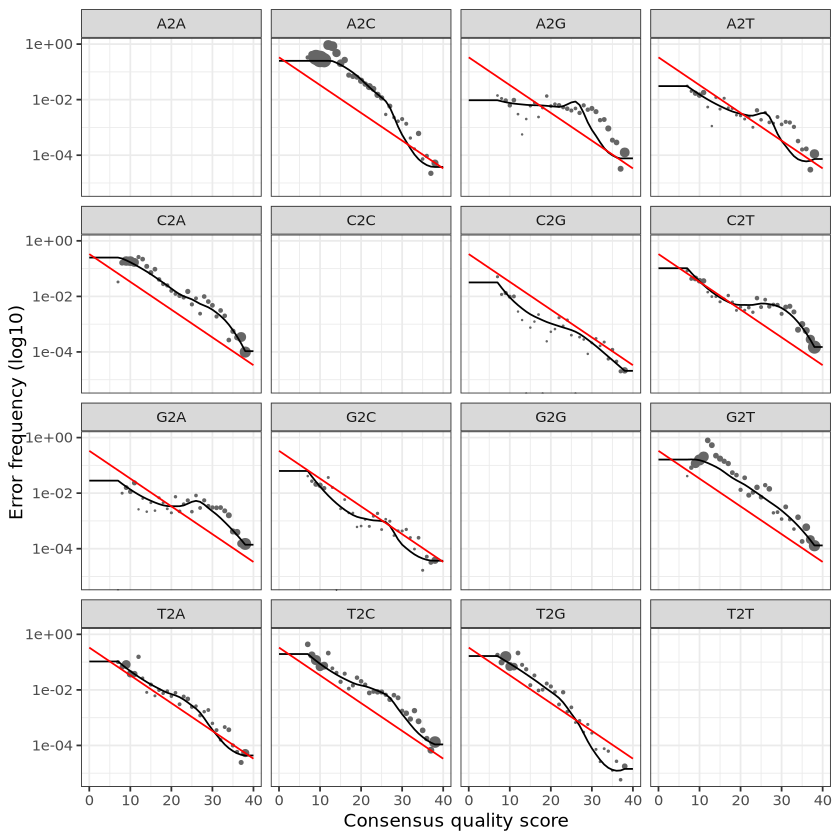

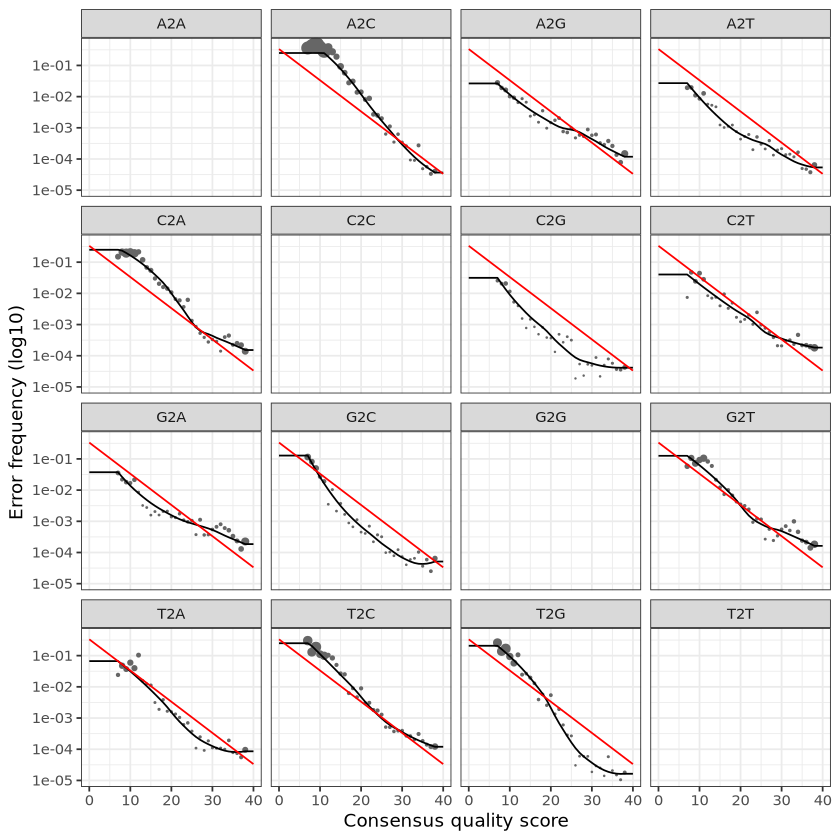

In [8]:
err_f <- dada2::learnErrors(unname(filt_f[kept_ids]), multithread=threads)
err_r <- dada2::learnErrors(unname(filt_r[kept_ids]), multithread=threads)
saveRDS(list(err_f=err_f, err_r=err_r), file.path(outdir, "error_models.rds"))
print(dada2::plotErrors(err_f, nominalQ=TRUE))
print(dada2::plotErrors(err_r, nominalQ=TRUE))

## 8. Дерепликация и денойзинг DADA2

`derepFastq()` группирует идентичные прочтения, `dada()` определяет реальные варианты с использованием моделей ошибок. R1/R2 обрабатываются отдельно. Результаты этой ячейки не являются итоговой таблицей ASV до объединения пар и удаления химер.

In [9]:
derep_f <- dada2::derepFastq(unname(filt_f[kept_ids]), verbose=FALSE)
derep_r <- dada2::derepFastq(unname(filt_r[kept_ids]), verbose=FALSE)
names(derep_f) <- names(derep_r) <- kept_ids
dada_f <- dada2::dada(derep_f, err=err_f, pool=pooling, multithread=threads)
dada_r <- dada2::dada(derep_r, err=err_r, pool=pooling, multithread=threads)
stopifnot(identical(names(dada_f), kept_ids), identical(names(dada_r), kept_ids))
saveRDS(list(dada_f=dada_f, dada_r=dada_r,
             derep_f=derep_f, derep_r=derep_r),
        file.path(outdir, "denoised_pairs.rds"))
cat("Denoised samples:", length(dada_f), "\n")

Sample 1 - 158183 reads in 12340 unique sequences.
Sample 2 - 94668 reads in 8296 unique sequences.
Sample 3 - 73865 reads in 7908 unique sequences.
Sample 4 - 53346 reads in 5568 unique sequences.
Sample 5 - 43543 reads in 4165 unique sequences.
Sample 6 - 140478 reads in 8641 unique sequences.
Sample 7 - 68096 reads in 4782 unique sequences.
Sample 8 - 37583 reads in 3236 unique sequences.
Sample 9 - 54595 reads in 5608 unique sequences.
Sample 10 - 60916 reads in 4492 unique sequences.
Sample 11 - 166190 reads in 16282 unique sequences.
Sample 12 - 83095 reads in 7259 unique sequences.
Sample 13 - 115922 reads in 8063 unique sequences.
Sample 14 - 118014 reads in 7392 unique sequences.
Sample 15 - 268566 reads in 28508 unique sequences.
Sample 16 - 100098 reads in 7560 unique sequences.
Sample 17 - 104404 reads in 7672 unique sequences.
Sample 18 - 98903 reads in 7471 unique sequences.
Sample 19 - 76015 reads in 9769 unique sequences.
Sample 20 - 58539 reads in 5452 unique sequences

## 9. Объединение пар, таблица ASV и удаление химер

`mergePairs()` требует перекрытие R1/R2 не менее 12 нуклеотидов; для ITS длинные ампликоны могут **не перекрываться**, и это нельзя исправлять искусственным конкатенированием без отдельного решения. При низкой сохранности объединения остановись для диагностики. `makeSequenceTable()` и `removeBimeraDenovo()` выполняются здесь, в правильном порядке.

In [10]:
mergers <- dada2::mergePairs(dada_f, derep_f, dada_r, derep_r,
                            minOverlap=min_overlap, maxMismatch=0, verbose=TRUE)
merge_counts <- vapply(mergers, function(z) sum(dada2::getUniques(z)), numeric(1))
merge_in <- pmin(vapply(dada_f, function(z) sum(dada2::getUniques(z)), numeric(1)),
                 vapply(dada_r, function(z) sum(dada2::getUniques(z)), numeric(1)))
merge_rate <- merge_counts / pmax(merge_in, 1)
merge_qc <- data.frame(sample_id=names(merge_counts), pairs_considered=merge_in,
                       merged=merge_counts, merged_pct=round(100*merge_rate, 2))
write_rows(merge_qc, "merge_success.tsv")
print(merge_qc, row.names=FALSE)
if (any(merge_rate < 0.5)) warning("Some samples have <50% merge success. Check ITS amplicon length/primers/quality")

seqtab_before_chimera <- dada2::makeSequenceTable(mergers)
seqtab_nochim <- dada2::removeBimeraDenovo(
  seqtab_before_chimera, method="consensus", multithread=threads)
if (!ncol(seqtab_nochim) || sum(seqtab_nochim)==0) stop("No non-chimeric ASVs remain")
saveRDS(seqtab_before_chimera, file.path(outdir, "seqtab_before_chimera.rds"))
saveRDS(seqtab_nochim, file.path(outdir, "seqtab_nochim.rds"))
cat("ASVs before chimera removal:", ncol(seqtab_before_chimera),
    "| after:", ncol(seqtab_nochim),
    "| non-chimeric reads:", sum(seqtab_nochim), "\n")

155948 paired-reads (in 163 unique pairings) successfully merged out of 158041 (in 270 pairings) input.

94341 paired-reads (in 73 unique pairings) successfully merged out of 94646 (in 88 pairings) input.

73496 paired-reads (in 169 unique pairings) successfully merged out of 73838 (in 193 pairings) input.

52597 paired-reads (in 154 unique pairings) successfully merged out of 53255 (in 200 pairings) input.

42564 paired-reads (in 97 unique pairings) successfully merged out of 43519 (in 162 pairings) input.

138234 paired-reads (in 26 unique pairings) successfully merged out of 140203 (in 66 pairings) input.

65913 paired-reads (in 51 unique pairings) successfully merged out of 68087 (in 129 pairings) input.

37080 paired-reads (in 53 unique pairings) successfully merged out of 37574 (in 108 pairings) input.

54260 paired-reads (in 37 unique pairings) successfully merged out of 54541 (in 66 pairings) input.

59520 paired-reads (in 78 unique pairings) successfully merged out of 60648 (i

 sample_id pairs_considered merged merged_pct
        S1           158075 155948      98.65
       S10            94649  94341      99.67
       S11            73847  73496      99.52
       S12            53270  52597      98.74
       S13            43521  42564      97.80
       S15           140318 138234      98.51
       S16            68088  65913      96.81
       S17            37576  37080      98.68
       S18            54546  54260      99.48
       S19            60672  59520      98.10
        S2           165952 160703      96.84
       S20            83008  80986      97.56
       S21           115810 111697      96.45
       S22           117904 116184      98.54
        S3           268174 263521      98.26
        S4            99925  97386      97.46
        S5           104297 101297      97.12
        S7            98769  97953      99.17
        S8            75988  75196      98.96
        S9            58529  57641      98.48
ASVs before chimera removal: 1140 

## 10. Таксономия: UNITE v10.0, General FASTA (all eukaryotes)

Используем `assignTaxonomy()` с `tryRC=TRUE` и семью рангами; `addSpecies()` не требуется, т. к. база UNITE содержит видовой уровень. Неоднозначные определения сохраняем как `NA`.

In [11]:
sequences <- colnames(seqtab_nochim)
tax_by_seq <- dada2::assignTaxonomy(sequences, taxonomy_ref,
  minBoot=min_boot, taxLevels=tax_levels, tryRC=try_rc,
  multithread=threads)
asv_ids <- paste0("ASV", sprintf("%06d", seq_along(sequences)))
seq_map <- setNames(sequences, asv_ids)
seqtab <- seqtab_nochim
colnames(seqtab) <- asv_ids
tax <- tax_by_seq
rownames(tax) <- asv_ids
stopifnot(identical(colnames(seqtab), rownames(tax)))
saveRDS(tax_by_seq, file.path(outdir, "taxonomy_by_sequence.rds"))
saveRDS(tax, file.path(outdir, "taxonomy_all_asvs.rds"))
saveRDS(seq_map, file.path(outdir, "asv_sequence_map.rds"))
write_matrix(tax_by_seq, "taxonomy_by_sequence.tsv")
write_matrix(tax, "taxonomy_all_asvs.tsv")
print(head(tax))
cat("Taxonomy assigned to:", nrow(tax), "ASVs\n")

UNITE fungal taxonomic reference detected.
          Kingdom            Phylum             Class                 
ASV000001 "k__Fungi"         "p__Ascomycota"    "c__Eurotiomycetes"   
ASV000002 NA                 NA                 NA                    
ASV000003 "k__Fungi"         "p__Ascomycota"    "c__Dothideomycetes"  
ASV000004 "k__Fungi"         "p__Ascomycota"    NA                    
ASV000005 "k__Viridiplantae" "p__Anthophyta"    "c__Eudicotyledonae"  
ASV000006 "k__Fungi"         "p__Basidiomycota" "c__Malasseziomycetes"
          Order                Family                   Genus            
ASV000001 "o__Chaetothyriales" "f__Herpotrichiellaceae" NA               
ASV000002 NA                   NA                       NA               
ASV000003 "o__Cladosporiales"  "f__Cladosporiaceae"     "g__Cladosporium"
ASV000004 NA                   NA                       NA               
ASV000005 "o__Caryophyllales"  "f__Caryophyllaceae"     "g__Dianthus"    
ASV000006 "o__Ma

## 11. Грибные ITS ASV, `phyloseq` и сохранение таблиц

UNITE all-eukaryotes может классифицировать и негрибные организмы. В отчёте сохраняем **все** ITS ASV, их таксономию и полный `phyloseq`; для дальнейшего грибного анализа по умолчанию оставляем только ASV с `Kingdom` содержащим `Fungi`. Неидентифицированные ASV сохраняются в полном наборе, но не включаются в строго грибную таблицу.

In [12]:
stopifnot(
  identical(colnames(seqtab), rownames(tax)),
  "Kingdom" %in% colnames(tax),
  identical(names(seq_map), colnames(seqtab))
)

full_mat <- seqtab
full_tax <- tax

# Классификация ASV по царству
kingdom <- trimws(as.character(tax[, "Kingdom"]))

group <- ifelse(
  is.na(kingdom) | kingdom == "", "Unassigned",
  ifelse(kingdom == "k__Fungi", "Fungi", "Non-fungal")
)

print(table(group))

# Для основного анализа оставляем только Fungi
excluded <- group != "Fungi"

cat("Excluded ASVs:", sum(excluded), "\n")

audit <- data.frame(
  ASV = rownames(tax),
  Kingdom = kingdom,
  Group = group,
  Reads = colSums(full_mat),
  Excluded = excluded
)

write_rows(audit, "taxonomy_filter_audit.tsv")

# Полные данные до фильтрации
write_matrix(full_mat, "asv_counts_all.tsv")
saveRDS(full_mat, file.path(outdir, "asv_counts_all.rds"))

# Грибные ASV
mat <- full_mat[, !excluded, drop=FALSE]
tax_target <- full_tax[!excluded, , drop=FALSE]

mat <- mat[rowSums(mat) > 0, , drop=FALSE]

if (nrow(mat) == 0 || ncol(mat) == 0)
  stop("No fungal ASVs remain")

tax_target <- tax_target[colnames(mat), , drop=FALSE]
stopifnot(identical(colnames(mat), rownames(tax_target)))

# Метаданные
meta_for_ps <- meta[
  match(rownames(mat), meta$sample_id), , drop=FALSE
]

if (anyNA(meta_for_ps$sample_id))
  stop("Missing metadata")

rownames(meta_for_ps) <- meta_for_ps$sample_id

# phyloseq для грибов
ps <- phyloseq::phyloseq(
  phyloseq::otu_table(mat, taxa_are_rows=FALSE),
  phyloseq::tax_table(as.matrix(tax_target)),
  phyloseq::sample_data(meta_for_ps)
)

# phyloseq со ВСЕМИ ITS ASV
meta_all <- meta[
  match(rownames(full_mat), meta$sample_id), , drop=FALSE
]

if (anyNA(meta_all$sample_id))
  stop("Missing metadata for full ITS table")

rownames(meta_all) <- meta_all$sample_id

ps_all <- phyloseq::phyloseq(
  phyloseq::otu_table(full_mat, taxa_are_rows=FALSE),
  phyloseq::tax_table(as.matrix(full_tax)),
  phyloseq::sample_data(meta_all)
)

# Сохранение
write_matrix(mat, "asv_counts_target.tsv")
write_matrix(tax_target, "taxonomy_target.tsv")
write_rows(meta_for_ps, "metadata_target.tsv")

saveRDS(mat, file.path(outdir, "asv_counts_target.rds"))
saveRDS(tax_target, file.path(outdir, "taxonomy_target.rds"))
saveRDS(ps, file.path(outdir, "phyloseq.rds"))
saveRDS(ps_all, file.path(outdir, "phyloseq_all_ITS_asvs.rds"))

# FASTA всех ITS ASV
fasta <- Biostrings::DNAStringSet(unname(seq_map))
names(fasta) <- names(seq_map)

Biostrings::writeXStringSet(
  fasta, file.path(outdir, "asv_sequences_all.fasta")
)

# Итоговая статистика
cat("Total ITS ASVs:", ncol(full_mat), "\n")
cat("Fungal ASVs:", ncol(mat), "\n")
cat("Samples:", nrow(mat), "\n")
cat("Fungal reads:", sum(mat), "\n")
cat("Fungal reads (%):",
    round(100 * sum(mat) / sum(full_mat), 2), "\n")

group
     Fungi Non-fungal Unassigned 
       885         12        208 
Excluded ASVs: 220 
Total ITS ASVs: 1105 
Fungal ASVs: 885 
Samples: 20 
Fungal reads: 1645078 
Fungal reads (%): 85.13 


## 12. Прослеживание числа прочтений (read tracking)

Считаем потери на каждом этапе: исходные FASTQ → удаление праймеров → DADA2 → объединение → нехимерные последовательности → целевая группа. Это **разные единицы по этапам**, но они согласованно представлены как количество пар/объединённых прочтений.

In [13]:
get_n <- function(z) sum(dada2::getUniques(z))
track <- data.frame(sample_id=sample_ids,
  raw_pairs=cut_qc$raw_pairs,
  after_cutadapt=cut_qc$trimmed_pairs,
  filtered=as.numeric(filter_stats[,"reads.out"]),
  denoisedF=NA_real_, denoisedR=NA_real_, merged=NA_real_,
  nonchim=NA_real_, target=NA_real_, stringsAsFactors=FALSE)
rownames(track) <- track$sample_id
track[kept_ids,"denoisedF"] <- vapply(dada_f, get_n, numeric(1))
track[kept_ids,"denoisedR"] <- vapply(dada_r, get_n, numeric(1))
track[names(merge_counts),"merged"] <- as.numeric(merge_counts)
track[rownames(seqtab_nochim),"nonchim"] <- rowSums(seqtab_nochim)
track[rownames(mat),"target"] <- rowSums(mat)
track$retained_raw_pct <- round(100*track$target/track$raw_pairs, 2)
track$retained_trimmed_pct <- round(100*track$target/track$after_cutadapt, 2)
write_rows(track, "read_tracking.tsv")
saveRDS(track, file.path(outdir, "read_tracking.rds"))
print(track)

    sample_id raw_pairs after_cutadapt filtered denoisedF denoisedR merged
S1         S1    305983         302666   158183    158075    158130 155948
S10       S10    172353         170779    94668     94649     94656  94341
S11       S11    123075         121955    73865     73847     73848  73496
S12       S12     94185          93319    53346     53321     53270  52597
S13       S13     83150          82275    43543     43536     43521  42564
S15       S15    256852         254594   140478    140318    140360 138234
S16       S16    136001         134778    68096     68093     68088  65913
S17       S17     70381          69721    37583     37576     37576  37080
S18       S18     99607          98699    54595     54584     54546  54260
S19       S19    122517         121338    60916     60882     60672  59520
S2         S2    304455         301291   166190    165972    165952 160703
S20       S20    172370         170876    83095     83082     83008  80986
S21       S21    223931  

## 13. Альфа-разнообразие

`Observed`, Shannon, Simpson, Pielou рассчитываются на абсолютных счётчиках ASV. **Observed зависит от глубины секвенирования**, поэтому сравнивать Flight/Ground только по этому графику нельзя. Сохраняем значения и опубликованные метаданные.

    sample_id  reads Observed   Shannon   Simpson    Pielou site_type
S1         S1 113780      132 2.1742137 0.7387584 0.4452799    Flight
S10       S10  73208       56 2.1097503 0.7051755 0.5241158    Ground
S11       S11  63097      125 2.6456874 0.7844176 0.5479527    Ground
S12       S12  38237      111 2.1299170 0.6401081 0.4522568    Ground
S13       S13  39447       78 1.8021319 0.5575757 0.4136452    Flight
S15       S15 126608       21 1.2245232 0.4581498 0.4022054    Flight
S16       S16  62864       43 0.9336672 0.2755623 0.2482365    Ground
S17       S17  34912       43 1.1698903 0.4018255 0.3110418    Flight
S18       S18  40473       30 1.9672646 0.6683227 0.5784035    Ground
S19       S19  55744       64 1.5096255 0.4376717 0.3629882    Flight
S2         S2 139189      109 1.3021410 0.3696531 0.2775622    Ground
S20       S20  75139       73 2.1797214 0.6667062 0.5080392    Ground
S21       S21  99989       51 1.6229409 0.5174175 0.4127703    Flight
S22       S22 110751

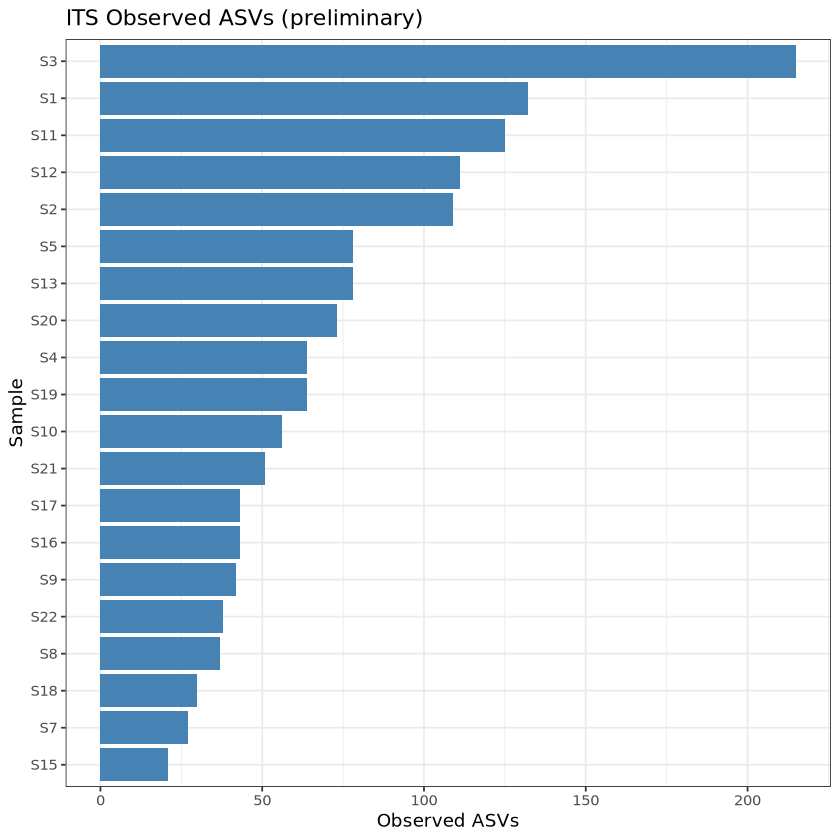

In [14]:
rel <- sweep(mat, 1, rowSums(mat), "/")
alpha <- data.frame(sample_id=rownames(mat), reads=rowSums(mat),
  Observed=rowSums(mat>0), Shannon=vegan::diversity(mat, "shannon"),
  Simpson=vegan::diversity(mat, "simpson"))
alpha$Pielou <- ifelse(alpha$Observed>1,
  alpha$Shannon/log(alpha$Observed), NA_real_)
for (field in intersect(c("site_type", "sampling_date", "altitude_min_m",
                          "altitude_max_m", "air_volume_m3", "dna_yield_ng_m3"), names(meta_for_ps)))
  alpha[[field]] <- meta_for_ps[match(alpha$sample_id, meta_for_ps$sample_id), field]
write_rows(alpha, "alpha_diversity.tsv")
saveRDS(alpha, file.path(outdir, "alpha_diversity.rds"))
write_matrix(rel, "asv_relative_abundance.tsv")
print(alpha)
p_alpha <- ggplot2::ggplot(alpha, ggplot2::aes(x=reorder(sample_id, Observed), y=Observed)) +
  ggplot2::geom_col(fill="steelblue") + ggplot2::coord_flip() +
  ggplot2::theme_bw() + ggplot2::labs(title=paste(marker, "Observed ASVs (preliminary)"),
                                    x="Sample", y="Observed ASVs")
print(p_alpha)
ggplot2::ggsave(file.path(outdir,"observed_ASVs.png"), p_alpha,
                width=7, height=6, dpi=160)

## 14. Кривые накопления ASV (rarefaction)

Проверяем достаточность глубины секвенирования по выборочным кривым, **без изменения основной ASV-таблицы**. Это диагностический график, а не автоматическая нормализация. При значительных различиях глубины дальнейшее сравнение Observed следует стандартизировать.

In [15]:
if (nrow(mat)>=2 && ncol(mat)>=2) {
  png(file.path(outdir,"rarefaction_curves.png"), width=1200, height=750, res=140)
  vegan::rarecurve(mat, step=max(1L, floor(min(rowSums(mat))/25)),
                   sample=min(rowSums(mat)), label=FALSE,
                   xlab="Sequenced reads", ylab="Observed ASVs",
                   main=paste(marker, "Rarefaction curves (diagnostic)"))
  dev.off()
  cat("Rarefaction curves saved. Min depth:", min(rowSums(mat)), "\n")
}

Rarefaction curves saved. Min depth: 34912 


## 15. Относительная численность родов

Объединяем ASV по `Genus`. Неопределённые рода обозначаем `Unclassified`, менее распространённые — `Other`. Все значения сохраняются в TSV, а не только показанные на графике.

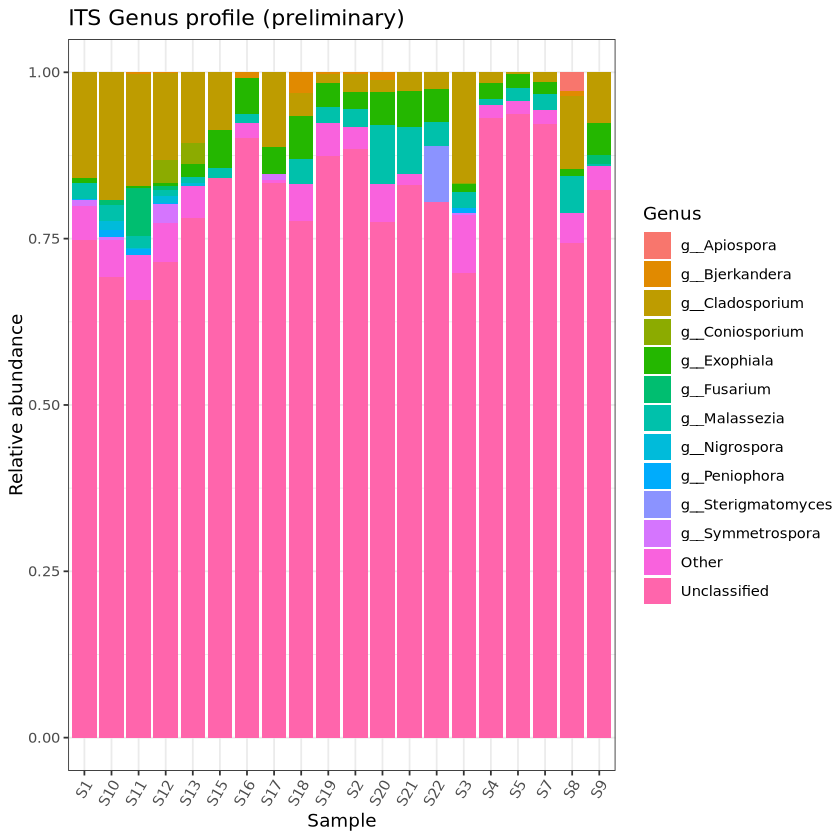

In [16]:
if (!"Genus" %in% colnames(tax_target)) stop("No Genus rank in taxonomy")
genus <- as.character(tax_target[colnames(rel), "Genus"])
genus[is.na(genus) | !nzchar(genus)] <- "Unclassified"
genus_rel <- t(rowsum(t(rel), group=genus, reorder=TRUE))
write_matrix(genus_rel, "relative_genus.tsv")
leaders <- head(names(sort(colMeans(genus_rel), decreasing=TRUE)), 12L)
plot_tab <- genus_rel[, leaders, drop=FALSE]
if (ncol(plot_tab)<ncol(genus_rel)) plot_tab <- cbind(plot_tab, Other=pmax(0, 1-rowSums(plot_tab)))
plot_df <- as.data.frame(as.table(plot_tab), stringsAsFactors=FALSE)
names(plot_df) <- c("Sample", "Genus", "Relative_abundance")
plot_df$Sample <- factor(plot_df$Sample, levels=rownames(genus_rel))
p_genus <- ggplot2::ggplot(plot_df, ggplot2::aes(Sample, Relative_abundance, fill=Genus)) +
  ggplot2::geom_col() + ggplot2::theme_bw() +
  ggplot2::theme(axis.text.x=ggplot2::element_text(angle=60, hjust=1)) +
  ggplot2::labs(title=paste(marker, "Genus profile (preliminary)"),
                x="Sample", y="Relative abundance")
print(p_genus)
ggplot2::ggsave(file.path(outdir, "genus_profiles.png"), p_genus,
                width=12, height=6, dpi=160)

## 16. Бета-разнообразие и PCoA

Bray–Curtis — на относительных численностях ASV; Jaccard — на присутствии/отсутствии. PCoA — обзорный график. Если присутствуют группы Flight/Ground и есть повторы, отдельно выполняем **PERMANOVA** и **анализ дисперсии групп**; PERMANOVA может отражать различия дисперсий, а не центров групп.

Permutation test for adonis under reduced model
Permutation: free
Number of permutations: 999

vegan::adonis2(formula = bray ~ site_type, data = perm_data, permutations = 999)
         Df SumOfSqs      R2      F Pr(>F)
Model     1  0.06633 0.04295 0.8077  0.602
Residual 18  1.47819 0.95705              
Total    19  1.54453 1.00000              
Analysis of Variance Table

Response: Distances
          Df   Sum Sq   Mean Sq F value Pr(>F)
Groups     1 0.013971 0.0139713  1.8597 0.1895
Residuals 18 0.135224 0.0075125               


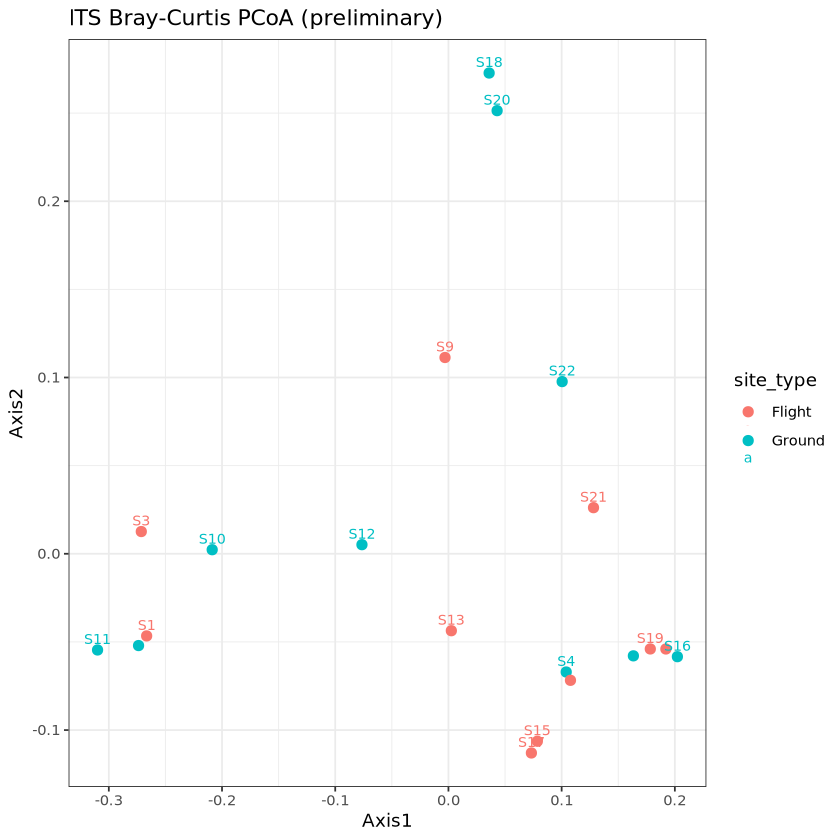

In [17]:
if (nrow(mat)>=3L && ncol(mat)>=2L) {
  bray <- vegan::vegdist(rel, method="bray")
  jaccard <- vegan::vegdist(mat>0, method="jaccard", binary=TRUE)
  write_matrix(as.matrix(bray), "bray_curtis.tsv")
  write_matrix(as.matrix(jaccard), "jaccard.tsv")
  pcoa <- stats::cmdscale(bray, k=2, eig=TRUE, add=TRUE)
  pcoa_df <- data.frame(sample_id=rownames(pcoa$points),
                        Axis1=pcoa$points[,1], Axis2=pcoa$points[,2])
  for (field in intersect(c("site_type","sampling_date"),names(meta_for_ps)))
    pcoa_df[[field]] <- meta_for_ps[match(pcoa_df$sample_id,meta_for_ps$sample_id),field]
  write_rows(pcoa_df, "pcoa_bray.tsv")
  p_pcoa <- if ("site_type" %in% names(pcoa_df))
    ggplot2::ggplot(pcoa_df, ggplot2::aes(Axis1, Axis2, color=site_type, label=sample_id))
  else ggplot2::ggplot(pcoa_df, ggplot2::aes(Axis1, Axis2, label=sample_id))
  p_pcoa <- p_pcoa + ggplot2::geom_point(size=2.5) +
    ggplot2::geom_text(vjust=-0.6, check_overlap=TRUE, size=3) +
    ggplot2::theme_bw() +
    ggplot2::labs(title=paste(marker,"Bray-Curtis PCoA (preliminary)"))
  print(p_pcoa)
  ggplot2::ggsave(file.path(outdir,"pcoa_bray.png"),p_pcoa,width=7,height=5,dpi=160)

  if ("site_type" %in% names(pcoa_df)) {
    group <- factor(meta_for_ps[match(rownames(mat),meta_for_ps$sample_id),"site_type"])
    if (all(!is.na(group)) && length(levels(group))==2 && all(table(group)>=2)) {
      perm_data <- data.frame(site_type=group, row.names=rownames(mat))
      perm <- vegan::adonis2(bray ~ site_type, data=perm_data, permutations=999)
      disp <- vegan::betadisper(bray, group)
      disp_test <- stats::anova(disp)
      writeLines(capture.output(perm),file.path(outdir,"permanova_flight_ground.txt"))
      writeLines(capture.output(disp_test),file.path(outdir,"betadisper_flight_ground.txt"))
      print(perm); print(disp_test)
    }
  }
} else cat("Too few ASVs or samples for beta diversity\n")

## 17. Связь с погодой и экстремальными событиями (если добавлены данные)

В исходных метаданных погода обозначена как `NA`: **не выдумываем** температуру, ветер, осадки или даты экстремальных событий. Если в `metadata/samples_pnas.tsv` добавлены настоящие поля `temp_c`, `rh_pct`, `wind_ms`, `precip_mm`, `pressure_hpa`, `pm25`, `pm10`, выполняем **разведочный** коэффициент Спирмена с Shannon. Если есть колонка `extreme_event` со значениями `TRUE/FALSE` (или 1/0), считаем распределение событий и описательную разницу. Нужны проверки сезонности, партия/высота, временные лаги и достоверность измерений для дипломных выводов.

In [18]:
weather_columns <- c("temp_c","rh_pct","wind_ms","precip_mm",
                     "pressure_hpa","pm25","pm10")
weather_rows <- list()
for (field in intersect(weather_columns, names(meta_for_ps))) {
  x <- suppressWarnings(as.numeric(meta_for_ps[alpha$sample_id, field]))
  y <- alpha$Shannon
  ok <- is.finite(x) & is.finite(y)
  if (sum(ok)>=8 && length(unique(x[ok]))>=3) {
    test <- suppressWarnings(stats::cor.test(x[ok],y[ok],method="spearman",exact=FALSE))
    weather_rows[[field]] <- data.frame(variable=field, n=sum(ok),
      rho=unname(test$estimate), p_value=test$p.value)
  }
}
if (length(weather_rows)) {
  weather_associations <- do.call(rbind,weather_rows)
  weather_associations$p_BH <- p.adjust(weather_associations$p_value,"BH")
  write_rows(weather_associations,"weather_shannon_spearman.tsv")
  print(weather_associations)
} else cat("Weather measurements not available or insufficient: no weather correlations.\n")
if ("extreme_event" %in% names(meta_for_ps)) {
  event <- as.character(meta_for_ps[alpha$sample_id,"extreme_event"])
  event[event %in% c("1","TRUE","true","T")] <- "TRUE"
  event[event %in% c("0","FALSE","false","F")] <- "FALSE"
  valid <- !is.na(event) & event %in% c("TRUE","FALSE")
  if (sum(valid)>0) {
    event_summary <- aggregate(alpha$Shannon[valid], list(extreme_event=event[valid]),
                               function(z) c(n=length(z), mean=mean(z),median=median(z)))
    print(event_summary)
    cat("Event categories: exploratory; not proof of causal weather effects.\n")
  }
}

Weather measurements not available or insufficient: no weather correlations.


## 18. Сводка и воспроизводимость

Сохраняются сведения о версии R, библиотек и программах. Весь анализ выполнен заново из исходных FASTQ; список результатов можно посмотреть в JupyterLab в папке `results/{marker}`. Для научной интерпретации проверь отрицательные контроли и реальные метеоданные.

In [19]:
writeLines(capture.output(sessionInfo()), file.path(outdir,"sessionInfo.txt"))
versions <- c(cutadapt=system2(Sys.which("cutadapt"),"--version",stdout=TRUE),
              fastqc=if (run_fastqc) paste(system2(Sys.which("fastqc"),"--version",stdout=TRUE),collapse=" ") else "not run",
              multiqc=if (run_fastqc) paste(system2(Sys.which("multiqc"),"--version",stdout=TRUE),collapse=" ") else "not run")
writeLines(paste(names(versions), versions, sep=" = "),file.path(outdir,"tool_versions.txt"))
cat("Finished:",marker,"\nSamples:",nrow(mat),"\nTarget ASVs:",ncol(mat),
    "\nFinal reads:",sum(mat),"\nOutput:",outdir,
    "\nNegative controls: not provided/verified; decontam not run.",
    "\nWeather: only analyzed if actual metadata supplied.",
    "\nSave the notebook with Ctrl+S.\n")

Warning message:
“‘timedatectl’ indicates the non-existent timezone name ‘n/a’”
Warning message:
“Your system is mis-configured: ‘/etc/localtime’ is not a symlink”
Warning message:
“‘/etc/localtime’ is not identical to any known timezone file”


Finished: ITS 
Samples: 20 
Target ASVs: 885 
Final reads: 1645078 
Output: /home/panishevasa/airlab/pipeline/results/ITS 
Negative controls: not provided/verified; decontam not run. 
Weather: only analyzed if actual metadata supplied. 
Save the notebook with Ctrl+S.
